In [3]:
# Project README: Text-to-Image Generation with Stable Diffusion v1.5

## 1. Project Overview
This project demonstrates how to set up, optimize, and run a **Text-to-Image Generation Pipeline** in Google Colab using Hugging Face's `diffusers` library and PyTorch.

### What this project does:
* **Library Installation**: Installs and configures state-of-the-art libraries for deep learning and diffusion model operations (`diffusers`, `transformers`, `accelerate`).
* **Model Setup**: Downloads and loads the pre-trained **Stable Diffusion v1.5** model.
* **Pipeline Optimization**: Optimizes GPU execution using half-precision (`torch.float16`) to decrease memory footprint and increase generation speed.
* **Single & Batch Image Generation**: Generates high-quality, customized synthetic images from text descriptions (prompts).
* **Visualization & Storage**: Automatically saves the generated images locally as `.png` files and plots them inline side-by-side using `matplotlib`.

---

## 2. Core Concepts Utilized & Why

### A. Diffusion Models & Stable Diffusion
* **Concept**: Generative models that learn to create data by reversing a gradual noisy process. Stable Diffusion operates in a compressed, low-dimensional space called **Latent Space** (making it highly computational-efficient compared to pixel-space diffusion).
* **Why**: It is the industry standard for generating high-fidelity visual assets from raw text, making complex art generation accessible to standard computing hardware.

### B. Mixed Precision (`torch.float16`)
* **Concept**: Reducing the numeric precision of the model weights from 32-bit floating-point (`fp32`) to 16-bit floating-point (`fp16`).
* **Why**:
  * **Memory Savings**: Cuts the required GPU VRAM roughly in half (from ~10GB to ~5GB), avoiding Out-Of-Memory (OOM) errors on consumer-grade or Colab GPUs.
  * **Inference Speed**: Speeds up computing iterations substantially on modern GPUs (like NVIDIA T4/A100) which have hardware dedicated to executing half-precision calculations.

### C. Pipeline abstraction via Hugging Face `diffusers`
* **Concept**: Bundling the complex pipeline elements (Text Encoder, UNet, VAE, and Scheduler) under a single high-level abstraction: `StableDiffusionPipeline`.
* **Why**: It reduces hundreds of lines of complex setup code down to a single function call (`pipe(prompt)`), allowing rapid prototyping.

---

## 3. How to Utilize these Learnings in Other Projects

The methodologies mastered in this project can be transferred directly to various AI and machine learning tasks:

### 1. Transferring Optimization Techniques (FP16 & Accelerate)
* **Application**: Whenever loading large language models (LLMs) like LLaMA/Mistral, or Computer Vision models like YOLO/ViT, always utilize `torch_dtype=torch.float16` or 8-bit quantization (`bitsandbytes`). This enables execution on hardware resource limits.

### 2. Expanding to Advanced Generative Workflows
* **Image-to-Image Translation**: By importing `StableDiffusionImg2ImgPipeline`, you can supply both a text prompt and an existing image to create stylized variants.
* **ControlNet / Inpainting**: Use learned spatial controls to edit existing images (e.g., swapping backgrounds, adding objects, or modifying specific items inside masks).

### 3. Automating Media & Asset Creation Pipelines
* **Application**: Wrap this generation script inside a web framework (like FastAPI or Streamlit) to create an automated graphic generator API for game dev assets, marketing banners, or blog cover pages based on dynamic inputs.

In [7]:
# Install necessary libraries:
# - diffusers: library for state-of-the-art diffusion models (Stable Diffusion)
# - transformers: API for utilizing pretrained models and tokenizers
# - torch: deep learning framework with GPU support
# - accelerate: utility library to run PyTorch models across different hardware configurations efficiently
!pip install diffusers transformers torch accelerate

In [8]:
# Install helper libraries:
# - ftfy: fixes broken Unicode text encoding issues
# - triton: compile framework for GPU programming, required by some optimal PyTorch features
!pip install ftfy
!pip install triton

In [9]:
# Import Stable Diffusion Pipeline from the diffusers library
from diffusers import StableDiffusionPipeline
# Import torch to handle GPU utilization and model precision datatypes
import torch

# Define the Hugging Face model repository path for Stable Diffusion v1-5
model_id = "runwayml/stable-diffusion-v1-5"

# Instantiate the pipeline from pre-trained weights
# Use torch.float16 (half-precision) to save GPU memory and speed up computation
pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

# Transfer the pipeline execution to GPU acceleration (CUDA) for fast generation
pipe = pipe.to("cuda")

# Set up a list of descriptive text prompts to be generated sequentially
prompts = [
    "A serene mountain lake at sunset",
    "A futuristic cityscape at night",
    "A magical forest with fireflies"
]

# Feed the prompts to the pipeline; it generates one 512x512 PIL image per prompt
images = pipe(
    prompt=prompts,
    num_images_per_prompt=1
).images

# Iterate through each generated image object to save and display
for i, image in enumerate(images, start=1):
    # Save the generated image file to the local directory
    image.save(f"generated_image_{i}.png")
    print(f"Saved: generated_image_{i}.png")
    # Open/display the image using the system's default viewer capability
    image.show()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Saved: generated_image_1.png
Saved: generated_image_2.png
Saved: generated_image_3.png


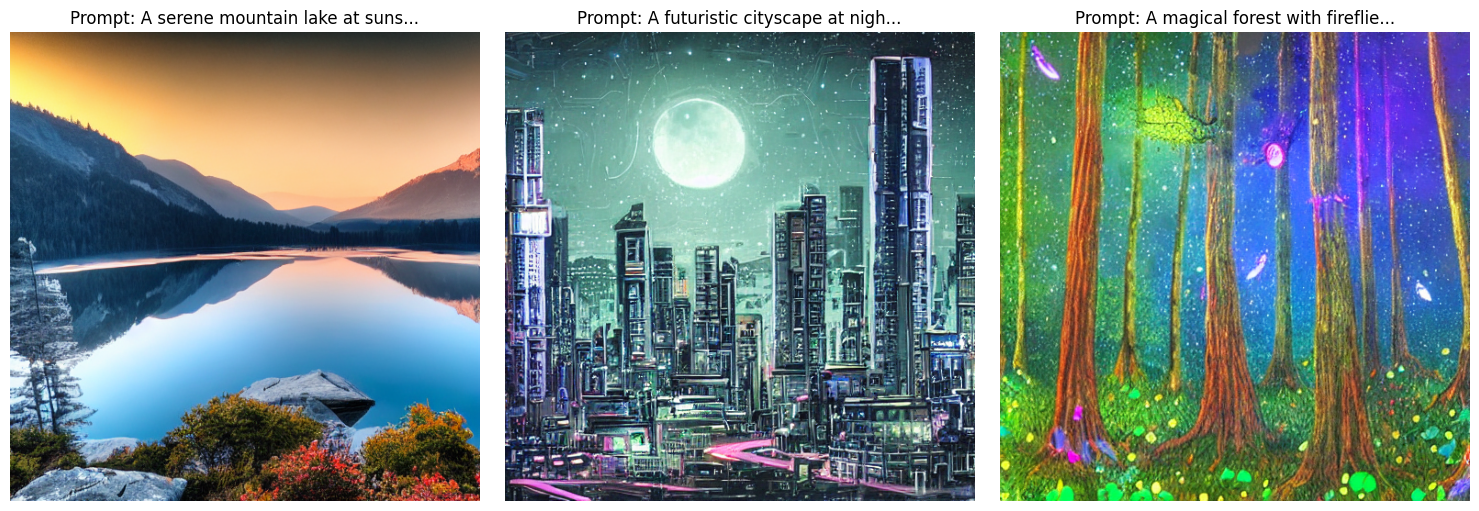

In [10]:
# Import matplotlib for creating customized image plots and grids
import matplotlib.pyplot as plt

# Initialize a layout of subplots in 1 row with columns matching the number of generated images
# figsize ensures that the final display layout is wide and large enough to inspect details
fig, axes = plt.subplots(1, len(images), figsize=(15, 5))

# Iterate and unpack both the images and corresponding prompt texts together
for i, (img, prompt) in enumerate(zip(images, prompts)):
    # Render the current image on the corresponding subplot axis
    axes[i].imshow(img)
    # Set a truncated version of the prompt text as the title for each subplot
    axes[i].set_title(f"Prompt: {prompt[:30]}...")
    # Hide the x and y axis coordinates and ticks for a clean output appearance
    axes[i].axis('off')

# Adjust padding between subplots to avoid overlapping elements
plt.tight_layout()
# Render the plot in the cell output
plt.show()

In [11]:
# Import Stable Diffusion Pipeline
from diffusers import StableDiffusionPipeline
# Import PyTorch to manage precision datatypes
import torch

# Specify the Stable Diffusion v1.5 repository
model_id = "runwayml/stable-diffusion-v1-5"

# Load the pipeline in half-precision (float16) to conserve GPU memory
pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

# Send model parameters to CUDA (GPU)
pipe = pipe.to("cuda")

# List containing a single targeted prompt
prompts = [
    "A serene mountain lake at sunset"
]

# Generate the single image based on the prompt
images = pipe(
    prompt=prompts,
    num_images_per_prompt=1
).images

# Loop over the single-item image list to save and show
for i, image in enumerate(images, start=1):
    # Save image as a PNG file locally
    image.save(f"generated_image_{i}.png")
    print(f"Saved: generated_image_{i}.png")
    # Display image on local output viewer
    image.show()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Saved: generated_image_1.png


  0%|          | 0/50 [00:00<?, ?it/s]

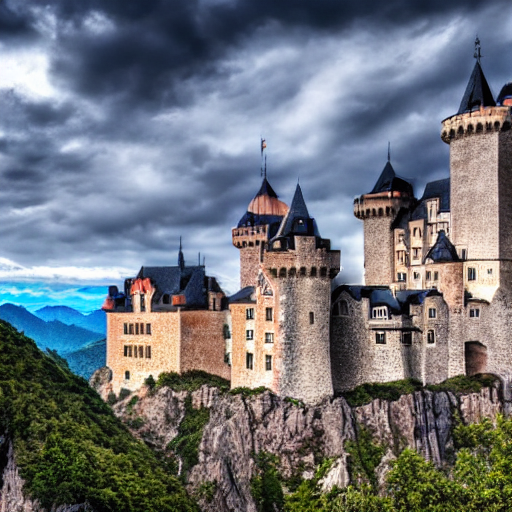

In [12]:
# Define the specific text prompt for image generation
prompt = "A majestic castle on top of a mountain"
# Generate the image and retrieve the first result object from the output
single_image = pipe(prompt=prompt).images[0]

# Save the generated PIL image object to a local PNG file
single_image.save("generated_single_image.png")

# Import the display tool to render standard objects directly in Colab output
from IPython.display import display
# Render the PIL image inline in the notebook's execution output
display(single_image)